intro_to_Language_modeling part1

[link](https://youtu.be/PaCmpygFfXo)

In [211]:
# download the training data
!curl https://raw.githubusercontent.com/karpathy/makemore/refs/heads/master/names.txt -o names.txt


  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  222k  100  222k    0     0   619k      0 --:--:-- --:--:-- --:--:--  618k


In [212]:
# read the file and create a list of words based on newline
words = open('names.txt','r').read().splitlines()
#min(len(w) for w in words)
#max(len(w) for w in words)
words[:2] # just checking first two items in list

['emma', 'olivia']

**Sample Bigram model**

A bigram model attempts to predict the probability of the correctness of a sequence of words or characters by predicting the occurrence of the one word or character after the other

In [213]:
b = {} # dictionary to store bigram and its occurence(count)
for w in words:
  chs = ['<S>'] + list(w) + ['<E>'] # adding a start and end constant token
  for ch1, ch2 in zip(chs,chs[1:]):
    bigram = (ch1, ch2) # tuple closest indivual characters
    b[bigram] = b.get(bigram,0) + 1 #adding k,v to dict. where value is the occurance/count

In [214]:
# sorts the dictionary by the second element(i.e count) in reverse order.
# By default the sort uses the first element in dict(ie key, which is bigram in this case), instead we sort by value(ie occurance/count)
sorted(b.items(), key = lambda kv: -kv[1])

[(('n', '<E>'), 6763),
 (('a', '<E>'), 6640),
 (('a', 'n'), 5438),
 (('<S>', 'a'), 4410),
 (('e', '<E>'), 3983),
 (('a', 'r'), 3264),
 (('e', 'l'), 3248),
 (('r', 'i'), 3033),
 (('n', 'a'), 2977),
 (('<S>', 'k'), 2963),
 (('l', 'e'), 2921),
 (('e', 'n'), 2675),
 (('l', 'a'), 2623),
 (('m', 'a'), 2590),
 (('<S>', 'm'), 2538),
 (('a', 'l'), 2528),
 (('i', '<E>'), 2489),
 (('l', 'i'), 2480),
 (('i', 'a'), 2445),
 (('<S>', 'j'), 2422),
 (('o', 'n'), 2411),
 (('h', '<E>'), 2409),
 (('r', 'a'), 2356),
 (('a', 'h'), 2332),
 (('h', 'a'), 2244),
 (('y', 'a'), 2143),
 (('i', 'n'), 2126),
 (('<S>', 's'), 2055),
 (('a', 'y'), 2050),
 (('y', '<E>'), 2007),
 (('e', 'r'), 1958),
 (('n', 'n'), 1906),
 (('y', 'n'), 1826),
 (('k', 'a'), 1731),
 (('n', 'i'), 1725),
 (('r', 'e'), 1697),
 (('<S>', 'd'), 1690),
 (('i', 'e'), 1653),
 (('a', 'i'), 1650),
 (('<S>', 'r'), 1639),
 (('a', 'm'), 1634),
 (('l', 'y'), 1588),
 (('<S>', 'l'), 1572),
 (('<S>', 'c'), 1542),
 (('<S>', 'e'), 1531),
 (('j', 'a'), 1473),
 (

In [215]:
# instead of using dictionary to store bigram and count we could use 2D tensor
# In this 2D tensor, rows are going to be the first char in bigram and columns the second char
# and each entry in this 2D gives the count of occurance of how often the second char follows the first
import torch

In [216]:
# a 2D tensor with initial values as int zero
N = torch.zeros((28,28), dtype=torch.int32)

In [217]:
chars = sorted(list(set(''.join(words)))) # a sorted list of all characters from words
stoi = {s:i for i,s in enumerate(chars)} # a dict of bigram:index
len(stoi) # this should be 26
stoi['<S>'] = 26 # special start token
stoi['<E>'] = 27 # special end token

In [218]:
for w in words:
  chs = ['<S>'] + list(w) + ['<E>']
  for ch1, ch2 in zip(chs, chs[1:]):
    ix1 = stoi[ch1]
    ix2 = stoi[ch2]
    N[ix1, ix2] += 1 # increment by 1 if character group appears repeatedly

In [219]:
itos = {i:s for s,i in stoi.items()} # a dict of index:bigram

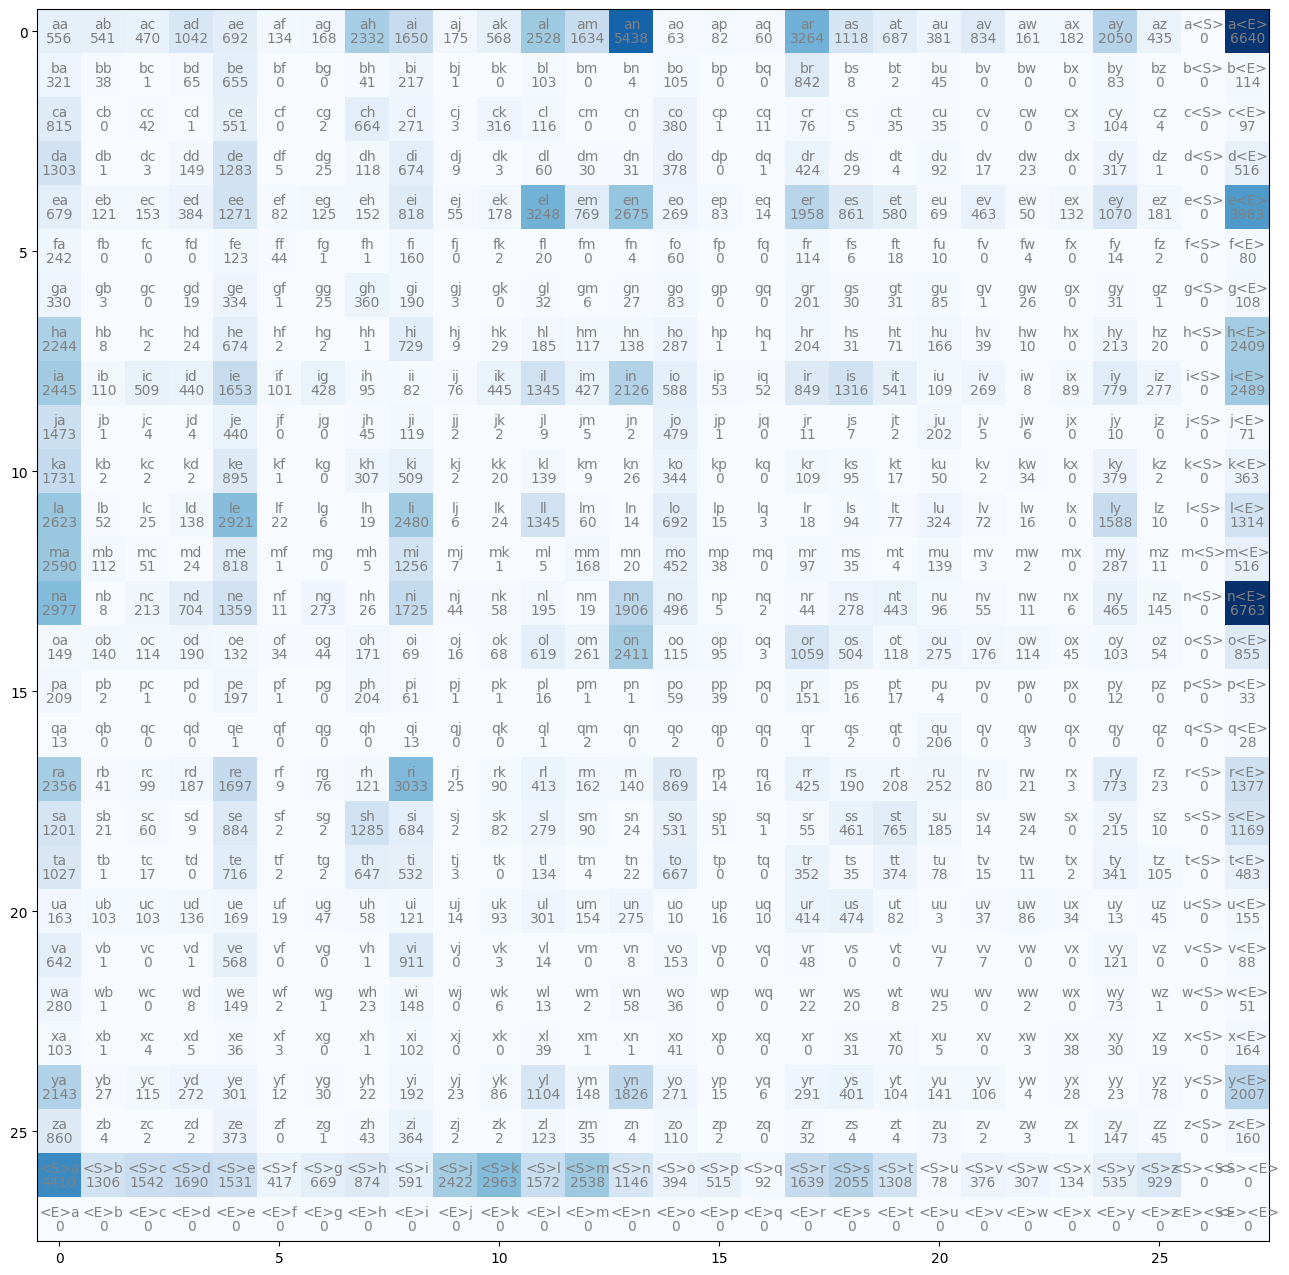

In [220]:
# ploting the 2D tensor
import matplotlib.pyplot as plt
%matplotlib inline

plt.figure(figsize=(16,16))
plt.imshow(N, cmap='Blues')
for i in range(28):
    for j in range(28):
        chstr = itos[i] + itos[j]
        plt.text(j, i, chstr, ha="center", va="bottom", color='gray')
        plt.text(j, i, N[i, j].item(), ha="center", va="top", color='gray')
#plt.axis('off');

In [221]:
# revised code, using '.' as the start/end token instead of '<S>' and '<E>'
# this elements the all zero value row for <E> and all zero column as shown in above ploted diagram
N = torch.zeros((27, 27), dtype=torch.int32)

In [222]:
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}

In [223]:
for w in words:
  chs = ['.'] + list(w) + ['.']
  for ch1, ch2 in zip(chs, chs[1:]):
    ix1 = stoi[ch1]
    ix2 = stoi[ch2]
    N[ix1, ix2] += 1

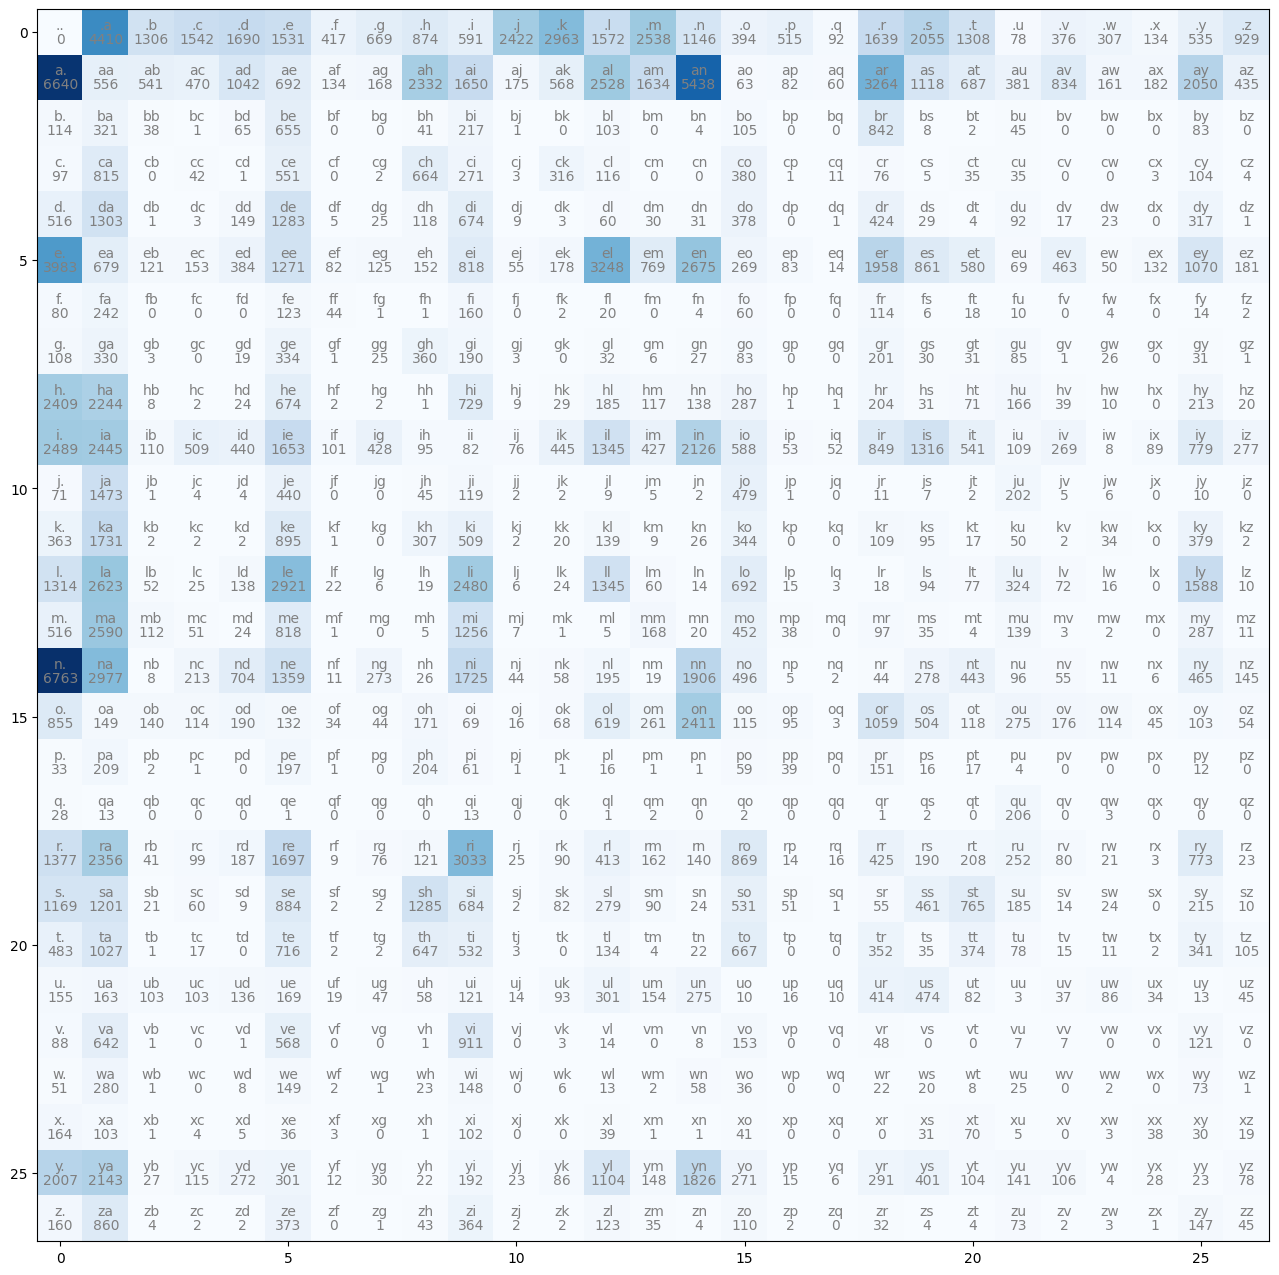

In [224]:
# ploting the 2D tensor
import matplotlib.pyplot as plt
%matplotlib inline

plt.figure(figsize=(16,16))
plt.imshow(N, cmap='Blues')
for i in range(27):
    for j in range(27):
        chstr = itos[i] + itos[j]
        plt.text(j, i, chstr, ha="center", va="bottom", color='gray')
        plt.text(j, i, N[i, j].item(), ha="center", va="top", color='gray')
#plt.axis('off');

In [225]:
# # optional: demonstarting the sampling using totch.multinomial With a randomly generated probablity distribution
# g = torch.Generator().manual_seed(2147483647) # generator used to make values deterministic
# p = torch.rand(3, generator=g) # 3 random values generated
# p = p / p.sum() # probablity distribution for the 3 values
# p # this should output tensor([0.6064, 0.3033, 0.0903])

# # do sampling using torch.multinomial
# torch.multinomial(p, num_samples=20, replacement=True, generator=g)

In [226]:
N[0] # first row values of 2d tensor

tensor([   0, 4410, 1306, 1542, 1690, 1531,  417,  669,  874,  591, 2422, 2963,
        1572, 2538, 1146,  394,  515,   92, 1639, 2055, 1308,   78,  376,  307,
         134,  535,  929], dtype=torch.int32)

In [227]:
p = N[0].float() # convert first row values to float
p = p/p.sum() # creating a probablity distribution for items in first row
p # since we have took first row, the probablities we get indicates how likely a single char be the starting char of a word

tensor([0.0000, 0.1377, 0.0408, 0.0481, 0.0528, 0.0478, 0.0130, 0.0209, 0.0273,
        0.0184, 0.0756, 0.0925, 0.0491, 0.0792, 0.0358, 0.0123, 0.0161, 0.0029,
        0.0512, 0.0642, 0.0408, 0.0024, 0.0117, 0.0096, 0.0042, 0.0167, 0.0290])

now generate samples from the probability distribution of first row

In [228]:
#generating just one sample
g = torch.Generator().manual_seed(2147483647) # generator used to make values deterministic
ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
print("index:",ix) # values could be diff each time
print("char:",itos[ix])

index: 10
char: j


In [233]:
# now we try generating sample based on our (first row's)distribution
g = torch.Generator().manual_seed(2147483647)

out = []
ix = 0
while True:
  p = N[ix].float() # row zero
  p = p/p.sum() # probablity distribution
  # get a sample based on probablity distribution of row
  ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
  #print(ix,itos[ix])
  out.append(itos[ix])

  if ix == 0:
    break
print(''.join(out))

junide.


In [242]:
# now we try generating sample based on couple of rows
g = torch.Generator().manual_seed(2147483647)

for i in range(5):
  out = []
  interout = {}
  ix = 0
  while True:
    # p = torch.ones(27)/27.0 # completely untrained where all values will be equally distributed

    p = N[ix].float() # row zero
    p = p/p.sum() # probablity distribution of row zero

    # get a sample based on probablity distribution of row zero
    ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()

    interout[ix] = itos[ix]
    out.append(itos[ix])

    if ix == 0:
      break
  outj = ''.join(out)
  print(outj, f'{interout=}')

junide. interout={10: 'j', 21: 'u', 14: 'n', 9: 'i', 4: 'd', 5: 'e', 0: '.'}
janasah. interout={10: 'j', 1: 'a', 14: 'n', 19: 's', 8: 'h', 0: '.'}
p. interout={16: 'p', 0: '.'}
cony. interout={3: 'c', 15: 'o', 14: 'n', 25: 'y', 0: '.'}
a. interout={1: 'a', 0: '.'}
